
<strong>Nama:</strong> Muhammad Rafly Romeo Nasution<br>
<strong>Kelas:</strong> 4KA25<br>
<strong>NPM:</strong> 10123875

---



# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Robotika Cerdas (Tingkat 4)


---
# Pertemuan IV

Pada praktikum ini, Anda akan melakukan generate musik menggunakan model LSTM (*Long Short-Term Memory*) untuk menghasilkan rangkaian nada dan melodi secara otomatis berdasarkan pola yang dipelajari dari data musik.


##**1. Importing Required Packages**


Instal dan impor seluruh library yang dibutuhkan untuk membaca MIDI, membangun model LSTM, mengolah data, serta memutar hasil musik.

In [1]:
# Menginstal library untuk membaca MIDI dan memutar audio
!pip install -q mido pretty_midi pyfluidsynth
!apt-get -qq update
!apt-get -qq install -y fluidsynth fluid-soundfont-gm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 106.1 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...

In [2]:
# Mengimpor library untuk mengolah file MIDI
import os
import numpy as np
import mido
from mido import MidiFile, MidiTrack, Message, MetaMessage

# Mengimpor komponen untuk membangun model LSTM
from keras.layers import LSTM, Dense, Activation, Dropout
from keras.models import Sequential
from tensorflow.keras.optimizers import Adam

# Mengimpor library untuk normalisasi data
from sklearn.preprocessing import MinMaxScaler

# Mengimpor library untuk mengonversi MIDI menjadi audio
import pretty_midi
from IPython.display import Audio, display

In [3]:
import warnings
warnings.filterwarnings("ignore")

##**2. Load MIDI Files**

Tahap ini bertujuan untuk memuat kumpulan file MIDI yang berisi data musik sebagai bahan pelatihan model LSTM. File ZIP diekstrak terlebih dahulu menggunakan perintah `unzip`, kemudian setiap file MIDI dibaca menggunakan pustaka `mido`. Program mengambil pesan MIDI yang bukan metadata, berada pada channel 0, dan bertipe `note_on`. Nilai nada (*pitch*) dari setiap pesan tersebut disimpan ke dalam list notes untuk digunakan pada tahap pemrosesan data dan pelatihan model.

In [4]:
# Memastikan file ZIP berada di lokasi yang sesuai sebelum diekstrak
# Jika belum ada di /content/, Colab akan meminta unggah chillhopdata.zip
import os
if not os.path.exists("/content/chillhopdata.zip"):
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        os.replace(name, "/content/chillhopdata.zip")

!unzip -o -q /content/chillhopdata.zip -d /content/chillhop
print("Ekstrak selesai")

Ekstrak selesai


In [5]:
notes = []

for root, dirs, files in os.walk("/content/chillhop"):
    for song in files:
        if song.lower().endswith((".mid", ".midi")):
            mid = MidiFile(os.path.join(root, song))

            for track in mid.tracks:
                for msg in track:
                    if (not msg.is_meta and
                        msg.type == "note_on" and
                        msg.velocity > 0 and
                        msg.channel == 0):
                        notes.append(msg.note)

print("Jumlah nada:", len(notes))

assert len(notes) > 0, "Tidak ada nada terbaca, cek isi chillhopdata.zip dan path /content/chillhop"

Jumlah nada: 3439


##**3. Scale Data**

Tahap ini bertujuan untuk menormalisasi nilai nada MIDI ke dalam rentang 0 hingga 1 menggunakan `MinMaxScaler`. Proses ini membantu menyamakan skala data sehingga model LSTM dapat mempelajari pola nada dengan lebih stabil.

In [6]:
# Menormalisasi nilai nada MIDI ke rentang 0 hingga 1
scaler = MinMaxScaler()
notes = scaler.fit_transform(np.array(notes).reshape(-1, 1)).flatten()

##**4. Create Train Data**

Tahap ini bertujuan untuk membagi data nada MIDI menjadi data input (`X`) dan target (`y`) agar dapat digunakan untuk melatih model LSTM. Setiap input terdiri dari 30 nada sebelumnya yang digunakan untuk memprediksi nada berikutnya. Sebanyak 300 urutan terakhir dipisahkan sebagai data pengujian (`X_test`), sedangkan data lainnya digunakan sebagai data pelatihan.

In [7]:
# Membentuk urutan input dan target untuk pelatihan model LSTM
n_prev = 30
X, y = [], []

for i in range(len(notes) - n_prev):
    X.append(notes[i:i + n_prev])
    y.append(notes[i + n_prev])

X = np.array(X).reshape(-1, n_prev, 1)
y = np.array(y)

# Memisahkan 300 sampel terakhir sebagai data pengujian
if len(X) > 300:
    X_test = X[-300:]
    X_train = X[:-300]
    y_train = y[:-300]
else:
    X_test = X[-max(1, len(X)//10):]
    X_train = X[:-len(X_test)]
    y_train = y[:-len(X_test)]

print("Data training:", X_train.shape)
print("Data pengujian:", X_test.shape)

Data training: (3109, 30, 1)
Data pengujian: (300, 30, 1)


##**5. Build LSTM**

Tahap ini bertujuan untuk membangun arsitektur model LSTM yang terdiri dari tiga lapisan LSTM dengan jumlah unit `256`, `128`, dan `64`, serta lapisan `Dropout` untuk mengurangi risiko overfitting. Lapisan `Dense` dan aktivasi linear digunakan untuk menghasilkan prediksi nilai nada berikutnya. Model kemudian dikompilasi menggunakan optimizer `Adam` dengan learning rate 0,001 dan fungsi loss mse untuk mengukur kesalahan prediksi.

In [8]:
# Membangun model LSTM untuk memprediksi nada musik berikutnya
model = Sequential([
    LSTM(256, input_shape=(n_prev, 1), return_sequences=True),
    Dropout(0.3),
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation="linear")])

model.summary()

# Mengompilasi model dengan optimizer Adam dan fungsi loss MSE
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 256)        │       264,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 30, 128)        │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 510,785 (1.95 MB)

 Trainable params: 510,785 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

##**6. Training**

Tahap ini bertujuan untuk melatih model LSTM menggunakan data input (`X`) dan target (`y`) agar model dapat mempelajari pola urutan nada musik dan memprediksi nada berikutnya. Proses pelatihan dilakukan selama 10 epoch dengan ukuran batch sebanyak 16 data. Selama pelatihan, model memperbarui parameternya untuk meminimalkan nilai loss sehingga prediksi nada menjadi lebih baik.

In [9]:
# Melatih model menggunakan data training selama 10 epoch
history = model.fit(X_train, y_train, batch_size=16, epochs=10, verbose=1)

Epoch 1/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 35s 127ms/step - loss: 0.0192
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 22s 113ms/step - loss: 0.0170
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 42s 117ms/step - loss: 0.0160
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - loss: 0.0162
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - loss: 0.0158
Epoch 6/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - loss: 0.0153
Epoch 7/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 26s 134ms/step - loss: 0.0156
Epoch 8/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - loss: 0.0150
Epoch 9/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 41s 115ms/step - loss: 0.0153
Epoch 10/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 24s 122ms/step - loss: 0.0151


##**7. Generating Music**

Tahap ini bertujuan untuk menghasilkan rangkaian nada musik berdasarkan prediksi model LSTM yang telah dilatih. Hasil prediksi dikembalikan ke skala nilai nada MIDI semula menggunakan `inverse_transform`, kemudian dikonversi menjadi bilangan bulat agar dapat digunakan sebagai pesan MIDI.

In [10]:
# Menghasilkan 300 nada baru berdasarkan pola yang dipelajari model
seed = X_test[0].copy()
generated = []

for _ in range(300):
    pred = model.predict(seed.reshape(1, n_prev, 1), verbose=0)[0, 0]
    generated.append(pred)

    # Menggeser urutan input dan memasukkan nada prediksi terbaru
    seed = np.roll(seed, -1, axis=0)
    seed[-1, 0] = pred

# Mengembalikan hasil prediksi ke skala nada MIDI
prediction = scaler.inverse_transform(
    np.array(generated).reshape(-1, 1)
).flatten()

# Membatasi nilai nada ke rentang MIDI yang valid
prediction = np.clip(np.rint(prediction), 0, 127).astype(int)

print("Jumlah nada yang dihasilkan:", len(prediction))

Jumlah nada yang dihasilkan: 300


##**8. Saving MIDI Music**

Menyimpan hasil prediksi ke file MIDI dengan pesan `note_on` dan `note_off` agar setiap nada memiliki durasi yang jelas.

In [11]:
# Membuat file MIDI dengan tempo 120 BPM dan durasi nada teratur
mid = MidiFile(ticks_per_beat=480)
track = MidiTrack()
mid.tracks.append(track)

track.append(MetaMessage("set_tempo", tempo=500000, time=0))

for note in prediction:
    # Memainkan nada selama satu ketukan, lalu menghentikannya
    track.append(Message(
        "note_on", channel=0, note=int(note),
        velocity=90, time=0
    ))
    track.append(Message(
        "note_off", channel=0, note=int(note),
        velocity=0, time=480
    ))

mid.save("/content/LSTM_music.mid")

print("Musik berhasil disimpan sebagai LSTM_music.mid")

Musik berhasil disimpan sebagai LSTM_music.mid


##**9. Play Music in Notebook**

Mengonversi file MIDI menjadi audio menggunakan `FluidSynth`, lalu menampilkannya sebagai pemutar audio langsung di Notebook.

In [12]:
# Membaca file MIDI dan mengubahnya menjadi audio
midi = pretty_midi.PrettyMIDI("/content/LSTM_music.mid")

print("Jumlah instrumen:", len(midi.instruments))
print("Jumlah nada:", sum(len(inst.notes) for inst in midi.instruments))

# Mengonversi MIDI menjadi audio menggunakan SoundFont
audio = midi.fluidsynth(fs=22050)

# Memutar musik langsung di output notebook
display(Audio(audio, rate=22050))

Jumlah instrumen: 1
Jumlah nada: 300


# Instruksi Tugas Praktikum

1. Modifikasi kode program pada tahap Training dengan mengubah nilai `batch_size` dari 16 menjadi 32 dan `epochs` dari 10 menjadi 20. Jalankan program, kemudian amati perubahan nilai loss yang dihasilkan.

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 23s 161ms/step - loss: 0.0203
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 152ms/step - loss: 0.0163
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 153ms/step - loss: 0.0165
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 152ms/step - loss: 0.0159
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 21s 154ms/step - loss: 0.0159
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 153ms/step - loss: 0.0158
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 16s 167ms/step - loss: 0.0157
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 154ms/step - loss: 0.0154
Epoch 9/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 16s 165ms/step - loss: 0.0156
Epoch 10/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 20s 156ms/step - loss: 0.0155
Epoch 11/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 21s 161ms/step - loss: 0.0154
Epoch 12/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 155ms/step - loss: 0.0157
Epoch 13/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 21s 159ms/step - loss: 0.0148
Epoch 14/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 16s 163ms/step - loss: 0.0150
Epoch 15/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 

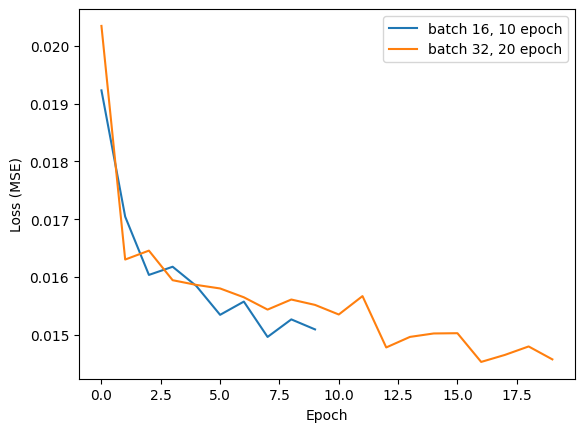

In [13]:
# CODE HERE
# Menyimpan hasil training awal (batch_size 16, 10 epoch) untuk pembanding
history_awal = history

# Membangun ulang model dari awal agar tidak melanjutkan bobot training sebelumnya
model = Sequential([
    LSTM(256, input_shape=(n_prev, 1), return_sequences=True),
    Dropout(0.3),
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation="linear")])
model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")

# Melatih model menggunakan data training dengan batch_size 32 selama 20 epoch
history = model.fit(X_train, y_train, batch_size=32, epochs=20, verbose=1)

# Membandingkan nilai loss sebelum dan sesudah modifikasi
import matplotlib.pyplot as plt

print("Loss awal   (bs 16, 10 epoch): %.6f -> %.6f" % (history_awal.history["loss"][0], history_awal.history["loss"][-1]))
print("Loss ubahan (bs 32, 20 epoch): %.6f -> %.6f" % (history.history["loss"][0], history.history["loss"][-1]))

plt.plot(history_awal.history["loss"], label="batch 16, 10 epoch")
plt.plot(history.history["loss"], label="batch 32, 20 epoch")
plt.xlabel("Epoch"); plt.ylabel("Loss (MSE)"); plt.legend(); plt.show()

In [14]:
# Berikan hasil analisis perubahan Anda disini
# Batch size dinaikkan dari 16 ke 32, jadi tiap update bobot memakai lebih banyak sampel.
# Jumlah update per epoch berkurang separuh, gradiennya lebih stabil, dan proses per epoch
# biasanya lebih cepat, tapi memori yang dipakai per batch jadi lebih besar.
# Epoch dinaikkan dari 10 ke 20, jadi model punya lebih banyak kesempatan mempelajari pola nada.
# Nilai loss (MSE) bisa dilihat pada grafik dan hasil print di atas. Loss turun seiring bertambahnya epoch,
# dan loss akhir pada 20 epoch dibandingkan dengan loss akhir pada 10 epoch.
# Penurunan yang makin melandai menandakan model mulai konvergen, jadi tambahan epoch
# tidak selalu memberi perbaikan besar.

2. Jelaskan fungsi penggunaan 30 nada sebelumnya (`n_prev = 30`) dalam proses prediksi musik menggunakan model LSTM.

Dengan menggunakan 30 nada sebelumnya, model LSTM dapat menangkap struktur melodis, ritme, dan ketergantungan jangka panjang dalam musik untuk memprediksi nada berikutnya secara harmonis.

In [15]:
# Berikan hasil analisis Anda disini
# n_prev = 30 artinya tiap input berisi 30 nada sebelumnya yang dipakai untuk memprediksi nada ke-31.
# Jumlah ini jadi jendela waktu (time steps) untuk LSTM, sehingga model bisa melihat konteks
# melodi dan ritme sebelumnya, tidak hanya satu nada terakhir.
# Kalau terlalu kecil konteksnya kurang, kalau terlalu besar komputasi makin berat.



---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma


https://www.praktikum-hpc.gunadarma.ac.id/